# Edges, contours and corners

Here we experimenting with preprocessing an image of an 
circuitboard to later be able to detect the components. 

The circuitboard has a lot of text, and i thought it would be
interesting to only find edges on the components. 

(A production pipeline would probably combine with OCR)

we will be using:
- masks on different color channels 
- contours

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [2]:
from cv_utils import (display,
                      display_grid,
                      ImageLoader
)

In [3]:
import os
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()
PROJECT_ROOT = Path(os.getenv("PROJECT_ROOT"))
DATA_DIR = Path(os.getenv("DATA_DIR"))

In [4]:
board_img_path = DATA_DIR.joinpath("assignments", "circuit_board.jpg")
board_output_path = DATA_DIR.joinpath("assignments", "output_circuit_board.png")


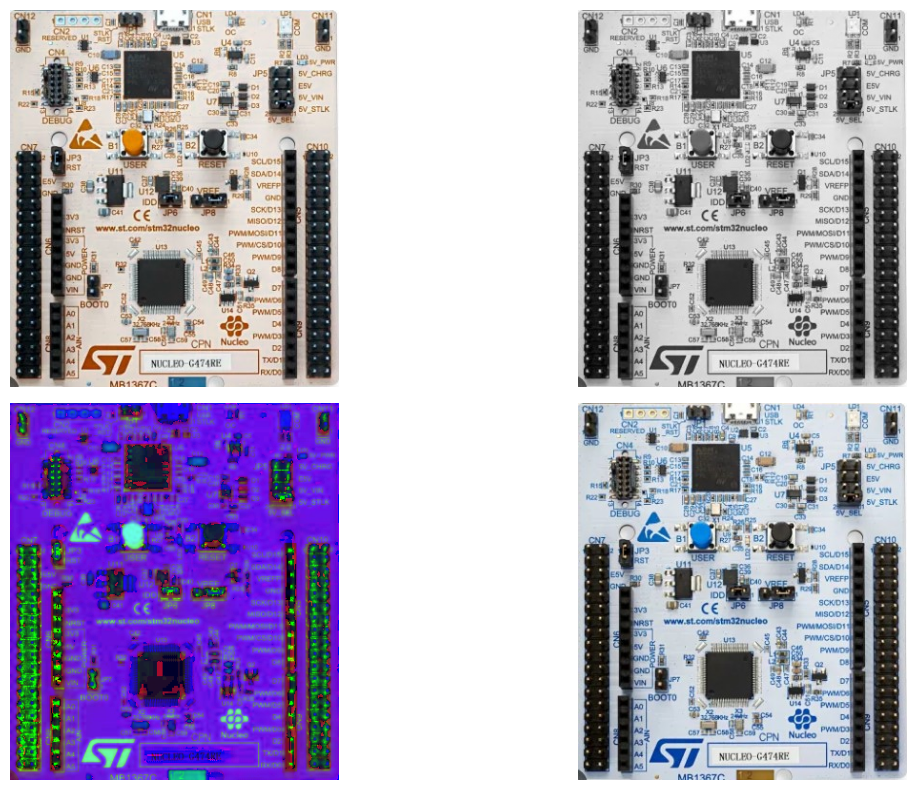

In [5]:
(board_bgr, board_gs,
 board_hsv, board_rgb) = ImageLoader.load_bgr_gs_hsv_rgb(board_img_path)

display_grid([board_bgr, board_gs, board_hsv, board_rgb], "gray")

# preprocessing with hsv

in the example picture, there are contours around everythin, not only components but texts, logotypes etc, which create a lot of noise.  

iwth hsv it should be easier to filter this.

![hsv color wheel](https://i.sstatic.net/UyDZ8.jpg)

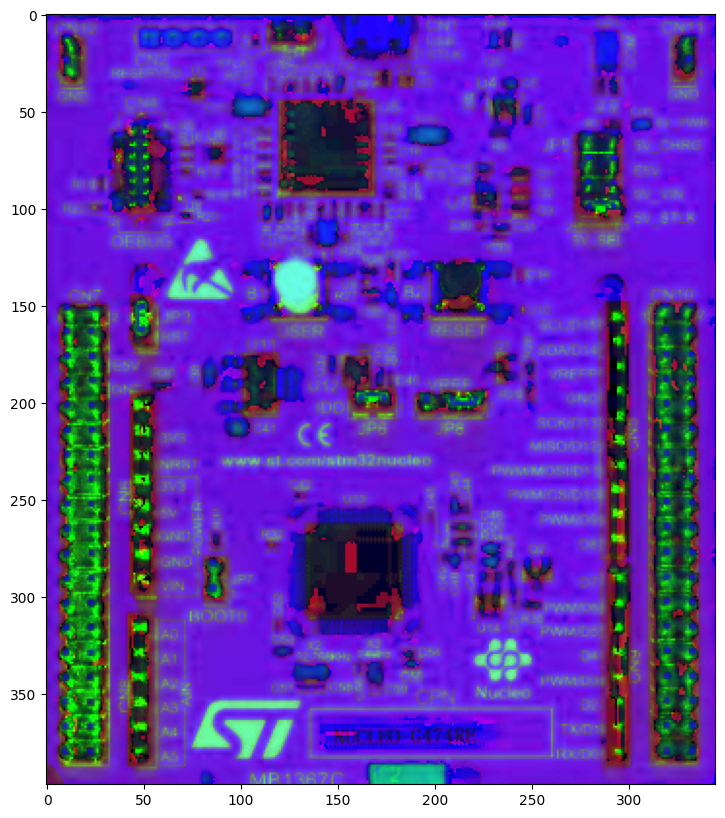

In [7]:
display(board_hsv)

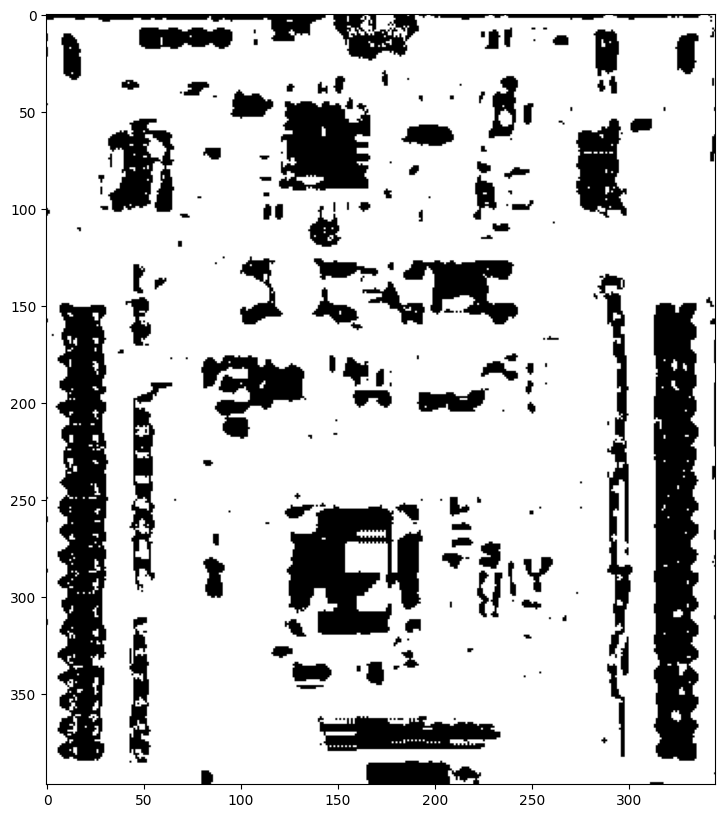

In [8]:
# Open CV uses hsv-scale - H: 0-179, S: 0-255, V: 0-255
# hue, saturation, value (brightness)
h, s, v = cv2.split(board_hsv)

# colormask: filter green-cyan text
# any pixel in either range becomes white
hsv_blue_mask = ((h >= 0) & (h <= 80) &
                 (s > 0) & (s < 255) &
                 (v > 0) & (v < 255)
                 ).astype(np.uint8) * 255

hsv_blue_mask = cv2.bitwise_not(hsv_blue_mask)
display(hsv_blue_mask, "gray")

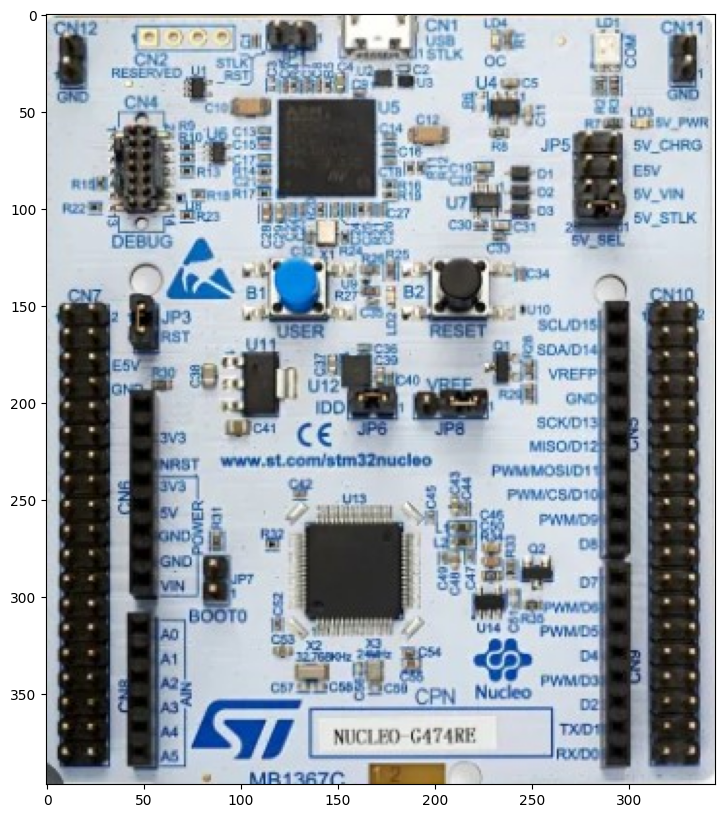

In [9]:
display(board_rgb)

lets try with rgb

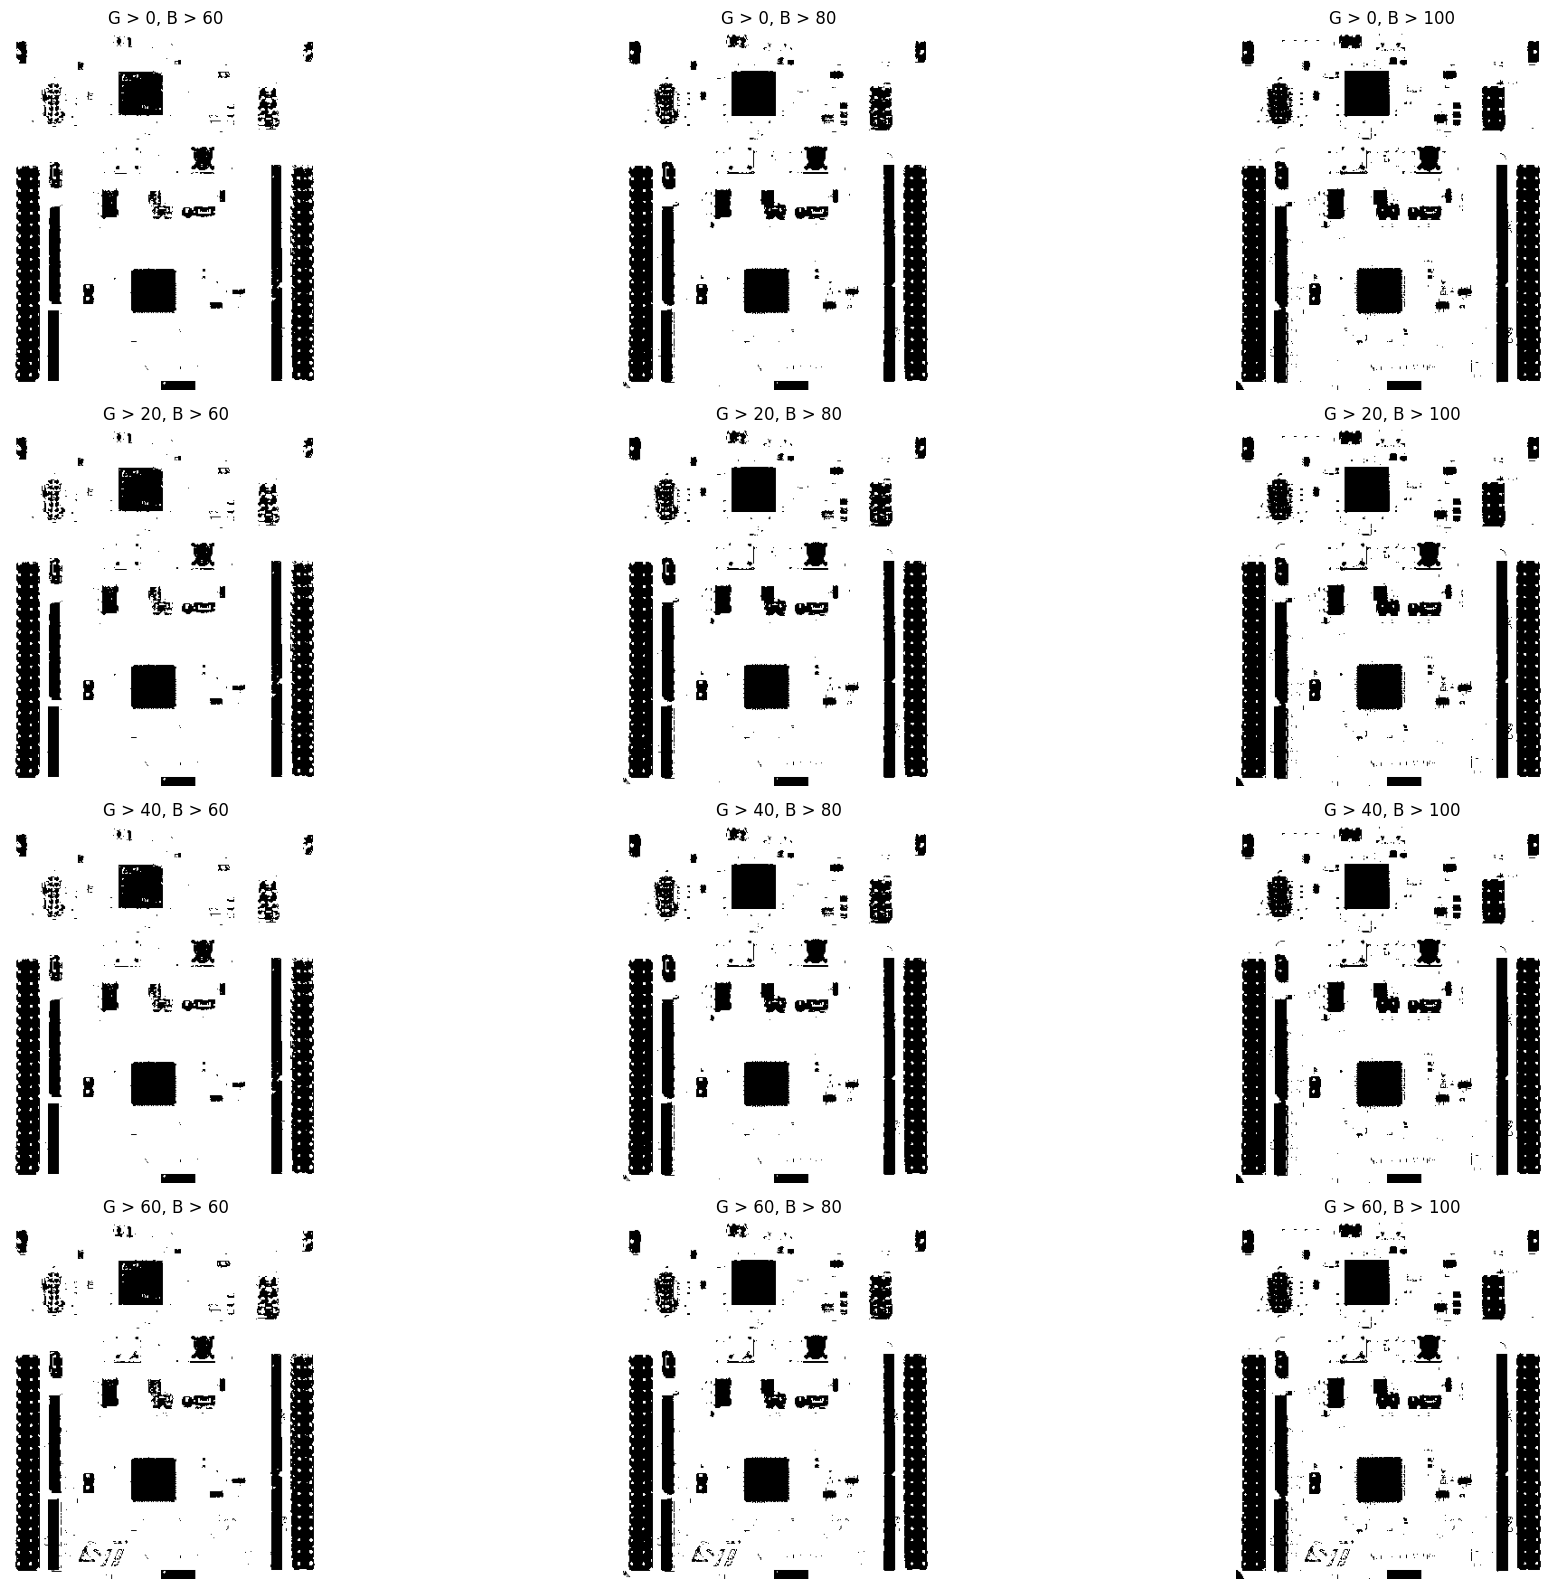

In [10]:
r, g, b = cv2.split(board_rgb)

masks = []
titles = []

for mask_g in range(0, 61, 20):
    for mask_b in range(60, 101, 20):
        mask = (g > mask_g) & (b > mask_b)
        masks.append(mask.astype(np.uint8) * 255)
        titles.append(f"G > {mask_g}, B > {mask_b}")

# print(titles)
display_grid(masks, "grey", max_cols=3, titles=titles)

In [11]:
mask_dict = dict(zip(titles, masks))
for item in mask_dict:
    print(item)

G > 0, B > 60
G > 0, B > 80
G > 0, B > 100
G > 20, B > 60
G > 20, B > 80
G > 20, B > 100
G > 40, B > 60
G > 40, B > 80
G > 40, B > 100
G > 60, B > 60
G > 60, B > 80
G > 60, B > 100


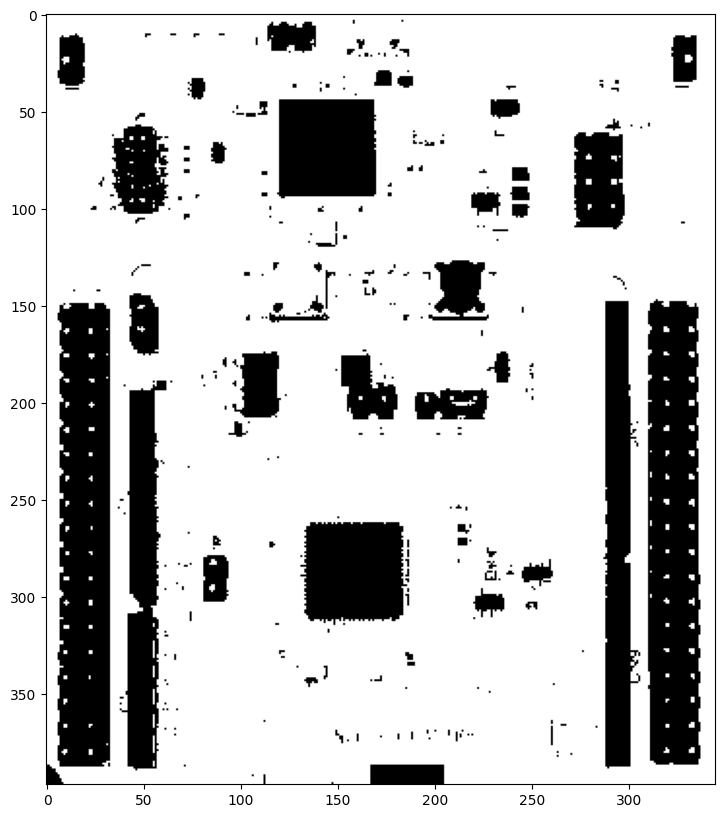

In [12]:
selected_blues_mask = mask_dict["G > 40, B > 100"]

display(selected_blues_mask, "gray")

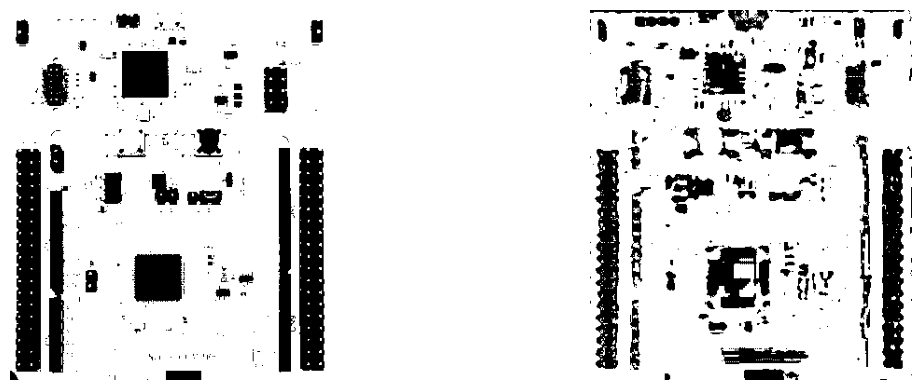

In [13]:
display_grid([selected_blues_mask, hsv_blue_mask], "grey")

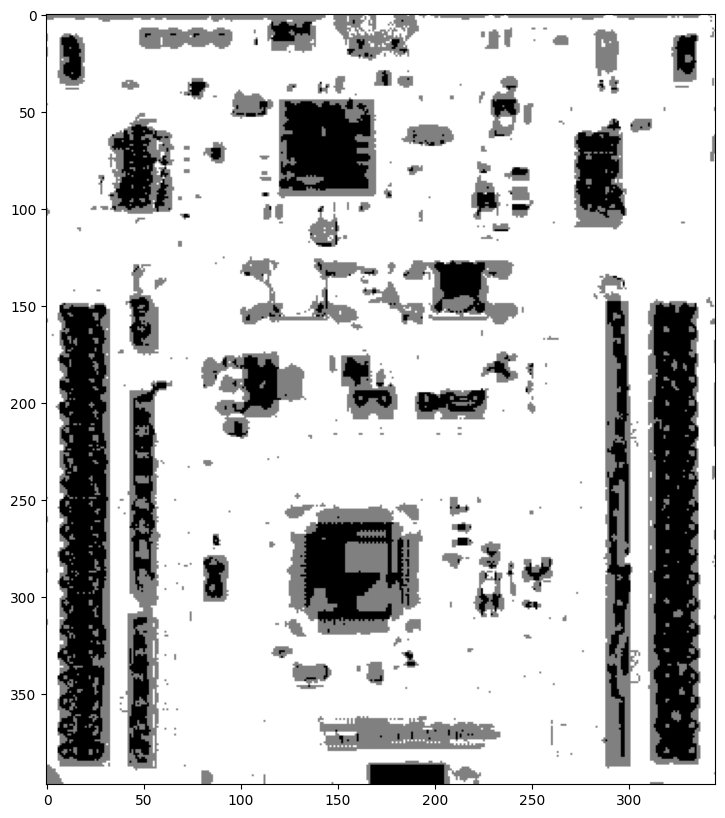

In [14]:
masks_overlay = cv2.addWeighted(selected_blues_mask,
                          0.5,
                          hsv_blue_mask,
                          0.5,
                          0
)

display(masks_overlay, "grey")

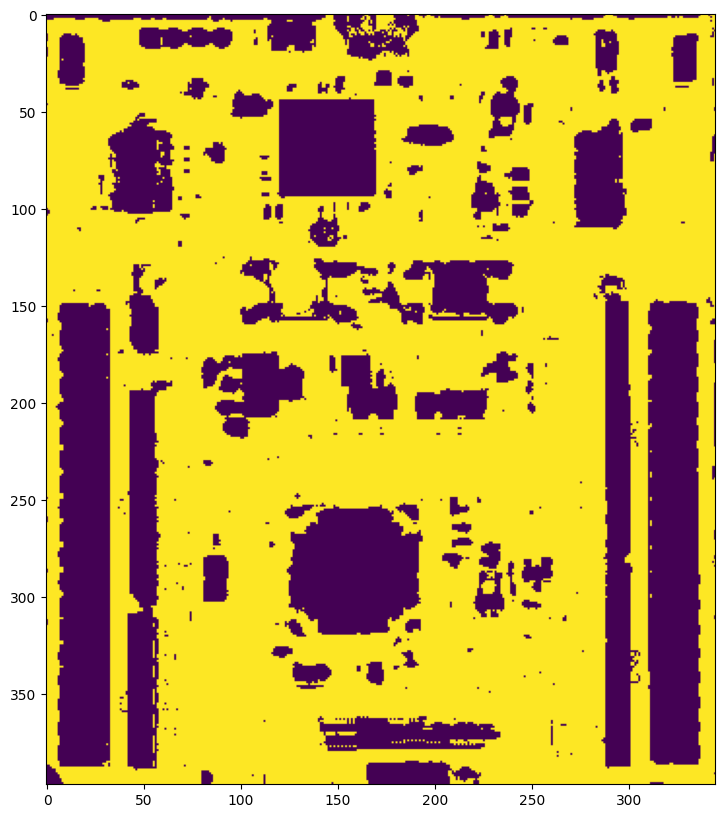

In [15]:
and_masks = np.bitwise_and(selected_blues_mask, hsv_blue_mask)

display(and_masks)

In [16]:
# we find contours
contours, hierarchy = cv2.findContours(and_masks,
                                        cv2.RETR_TREE,           # mode
                                        cv2.CHAIN_APPROX_SIMPLE) # discovery alg.

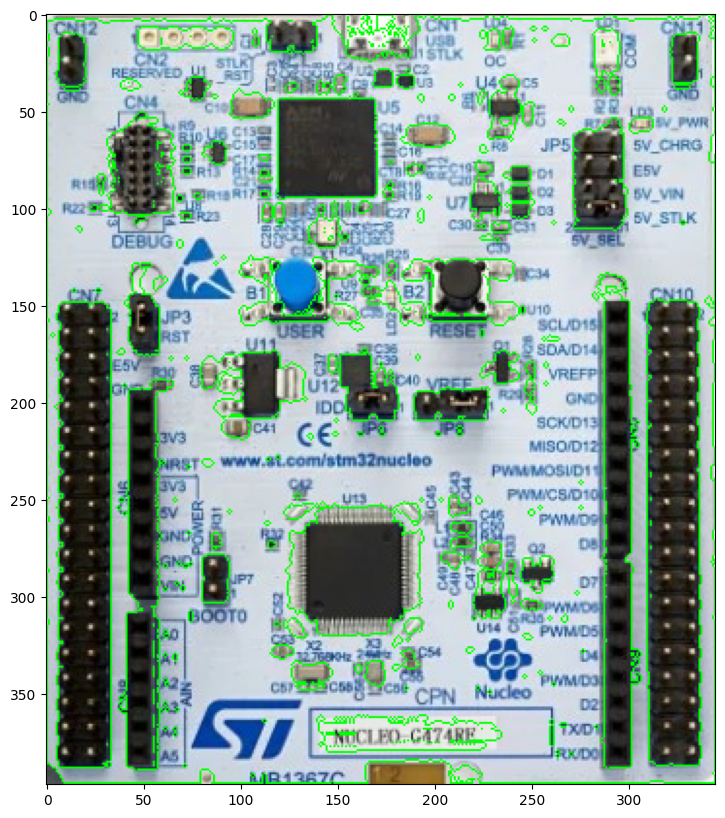

In [ ]:
img_contours = cv2.drawContours(board_rgb,
                                     contours,
                                     -1,             # all contours
                                     (0, 255, 0),
                                     1,              # thickness
                                     lineType=8,     # must be 4 or 8
                                     hierarchy=hierarchy,
                                     maxLevel=2
)
display(img_contours)

### corners

In [18]:
# Parameters for our AI model
max_corner = 60
quality_level = 0.001
min_distance = 5

corners = cv2.goodFeaturesToTrack(selected_blues_mask,
                                  max_corner,
                                  quality_level,
                                  min_distance)

# convert corners to int
corners = np.int16(corners)

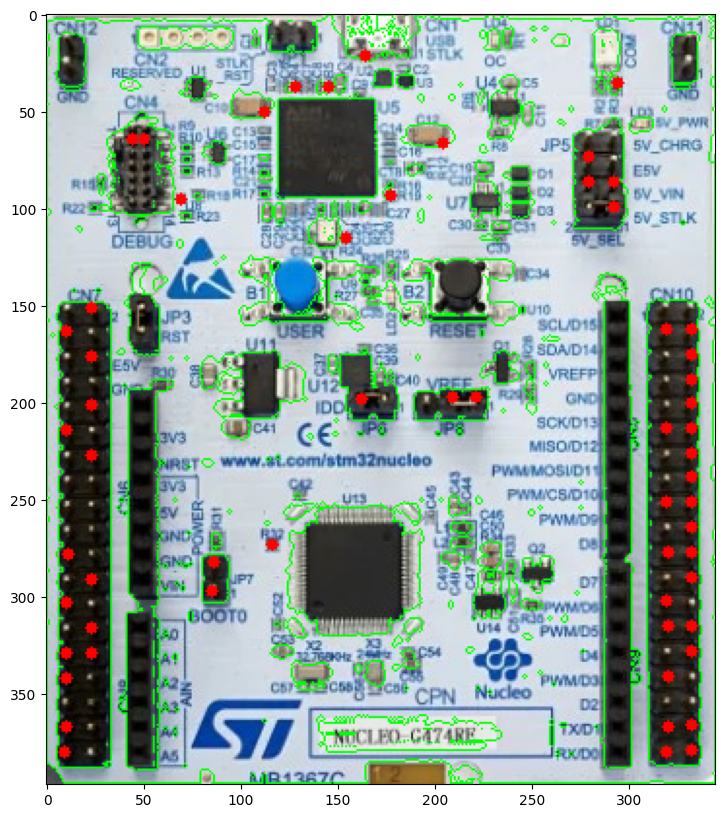

In [ ]:
for corner in corners:
    x,y = corner.ravel()
    cv2.circle(img_contours,
               (x,y),
               3,
               (255, 0, 0),
               -1)


display(img_contours)